In [94]:
!pip install category-encoders

In [95]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from category_encoders import TargetEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
%matplotlib inline
# !pip install category-encoders

In [96]:
# خواندن داده ها 
df = pd.read_csv("1632300362534233.csv")
df

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,1.850000e+09,61666.67
1,60,1,True,True,True,Shahran,1.850000e+09,61666.67
2,79,2,True,True,True,Pardis,5.500000e+08,18333.33
3,95,2,True,True,True,Shahrake Qods,9.025000e+08,30083.33
4,123,2,True,True,True,Shahrake Gharb,7.000000e+09,233333.33
...,...,...,...,...,...,...,...,...
3474,86,2,True,True,True,Southern Janatabad,3.500000e+09,116666.67
3475,83,2,True,True,True,Niavaran,6.800000e+09,226666.67
3476,75,2,False,False,False,Parand,3.650000e+08,12166.67
3477,105,2,True,True,True,Dorous,5.600000e+09,186666.67


In [97]:
# برسی اطلاعات
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3479 entries, 0 to 3478
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Area        3479 non-null   object 
 1   Room        3479 non-null   int64  
 2   Parking     3479 non-null   bool   
 3   Warehouse   3479 non-null   bool   
 4   Elevator    3479 non-null   bool   
 5   Address     3456 non-null   object 
 6   Price       3479 non-null   float64
 7   Price(USD)  3479 non-null   float64
dtypes: bool(3), float64(2), int64(1), object(2)
memory usage: 146.2+ KB


In [98]:
df.isnull().sum()

Area           0
Room           0
Parking        0
Warehouse      0
Elevator       0
Address       23
Price          0
Price(USD)     0
dtype: int64

In [99]:
# حذف ستون قیمت به دلار برای استفاده از یک متغیر وابسته و حذف مقادیر گمشده
df = df.drop(["Price(USD)"], axis=1)
df = df.dropna()

In [100]:
# حذف داده های معیوب از ستون Area 
df['Area'] = pd.to_numeric(
    df['Area'].astype(str).str.replace(',', '').str.strip(), 
    errors='coerce'
)
df = df[df['Area'] <= 900]
df = df.dropna(subset=['Area'])

In [101]:
# تبدیل عددی داده های parking, warehous و elevator  به صفر و یک
df[["Parking", "Warehouse", "Elevator"]] = df[["Parking", "Warehouse", "Elevator"]].astype(int)
df
"""این متغیر ها bool بودن و متغیر true برابر با 1 و false برابر با 0 میباشد """

'این متغیر ها bool بودن و متغیر true برابر با 1 و false برابر با 0 میباشد '

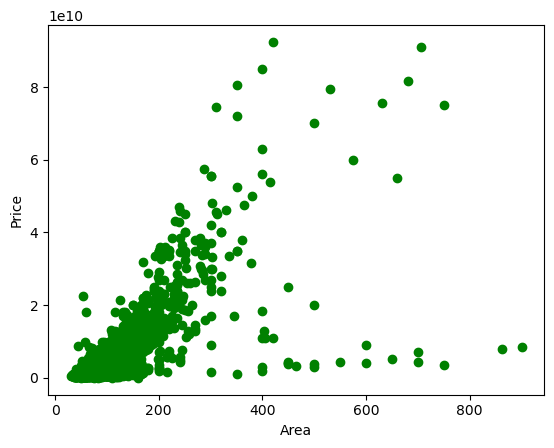

In [102]:
"""اینجا یک برسی رابطه انجام شده بین ستون متراژ و قیمت که خب اساسا امکان پیاده سازی هیج مدلی نیست"""
plt.scatter(df["Area"], df["Price"], color='Green')
plt.xlabel('Area')
plt.ylabel('Price')
plt.show()

{'whiskers': [<matplotlib.lines.Line2D at 0x14d28a5a490>,
 'caps': [<matplotlib.lines.Line2D at 0x14d28a5afd0>,
 'boxes': [<matplotlib.lines.Line2D at 0x14d28a22e90>],
 'medians': [<matplotlib.lines.Line2D at 0x14d28a5bed0>],
 'fliers': [<matplotlib.lines.Line2D at 0x14d28a5bd90>],
 'means': []}

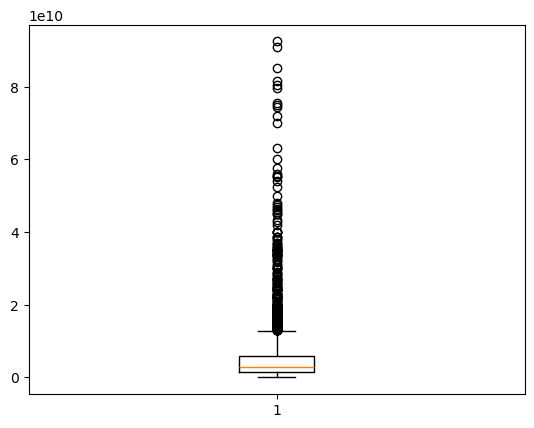

In [103]:
"""این نمودار جعبه ای هست برای قیمت که نشون دهنده داده های پرت زیاد به سمت بالاست که 
بیان گر اینه که نمودار هیستو گرام ما قراره یک چولگی شدید به سمت راست داشته باششه """
plt.boxplot(df["Price"])

In [104]:
# با لگاریتم گرفتن از ستون قیمت مقادیر رو فشرده میکنیم تا اختلاف بینشوون به حداقل برسه
df["Price"] = np.log1p(df["Price"])

{'whiskers': [<matplotlib.lines.Line2D at 0x14d28eb5450>,
 'caps': [<matplotlib.lines.Line2D at 0x14d28eb51d0>,
 'boxes': [<matplotlib.lines.Line2D at 0x14d28eb4e10>],
 'medians': [<matplotlib.lines.Line2D at 0x14d28eb4f50>],
 'fliers': [<matplotlib.lines.Line2D at 0x14d28eb5590>],
 'means': []}

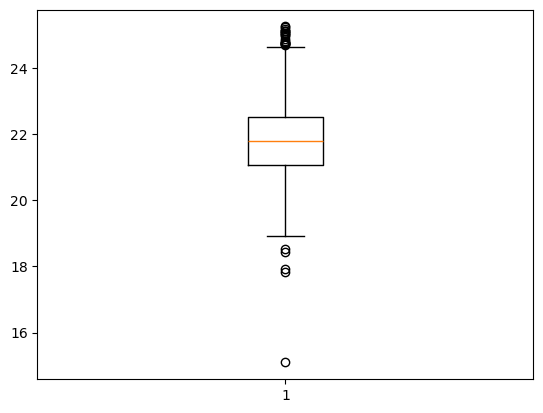

In [105]:
plt.boxplot(df["Price"])

In [106]:
# تابع iqr برای مدیریت داده های پرت
def remove_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_filtered = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
    return df_filtered

In [107]:
# حذف داده ها بر اساس iqr
df = remove_outliers(df, "Area")
df = remove_outliers(df, "Price")

(array([126., 475., 662., 650., 491., 287., 226., 144.,  79.,  65.]),
 array([ 30. ,  46.5,  63. ,  79.5,  96. , 112.5, 129. , 145.5, 162. ,
        178.5, 195. ]),
 <BarContainer object of 10 artists>)

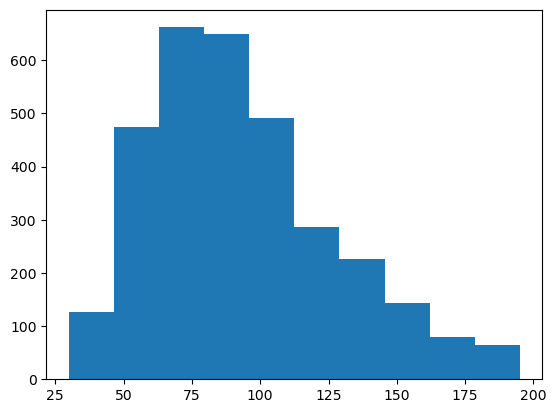

In [108]:
plt.hist(df["Area"])

(array([ 60., 187., 331., 368., 677., 655., 433., 341., 137.,  16.]),
 array([19.16261809, 19.66980756, 20.17699702, 20.68418648, 21.19137595,
        21.69856541, 22.20575487, 22.71294433, 23.2201338 , 23.72732326,
        24.23451272]),
 <BarContainer object of 10 artists>)

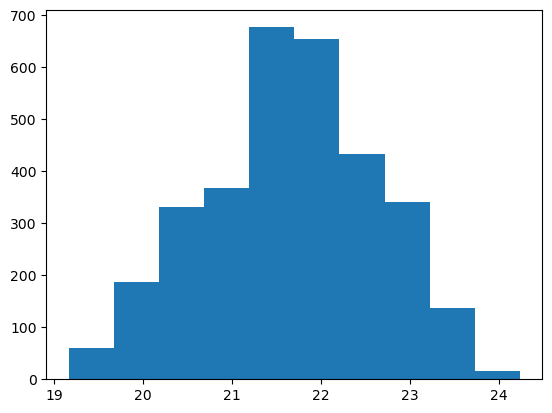

In [109]:
plt.hist(df["Price"])

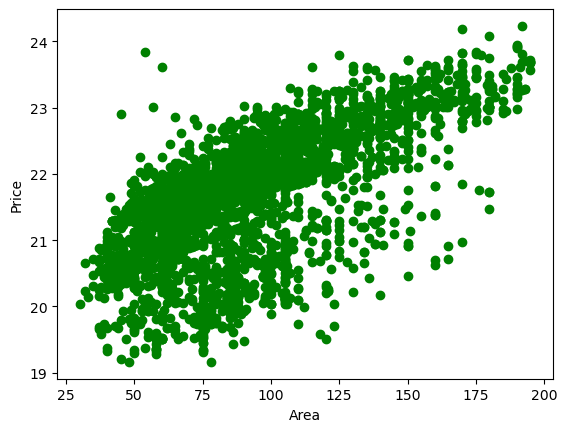

In [110]:
# برسی دوباره رابطه بین متراژ و قیمت
plt.scatter(df["Area"], df["Price"], color='Green')
plt.xlabel('Area')
plt.ylabel('Price')
plt.show()

In [111]:
#مدل سازی
#جداسازی داده ها
X = df[["Area", "Room", "Parking", "Warehouse", "Elevator", "Address"]]
y = df["Price"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)
# تبدیل ستون آدرس به داده های عددی
encoder = TargetEncoder(cols=['Address'])
X_train = encoder.fit_transform(X_train, y_train)
X_test = encoder.transform(X_test) 

In [112]:
# ساخت مدلpolynomial 
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [113]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled = scaler.transform(X_test_poly)

In [114]:
model = Ridge(alpha=1.0) 
model.fit(X_train_scaled, y_train)
y_pred_ridge = model.predict(X_test_scaled)
print(f"R2 Score: {r2_score(y_test, y_pred)}")

R2 Score: 0.8640799987724772


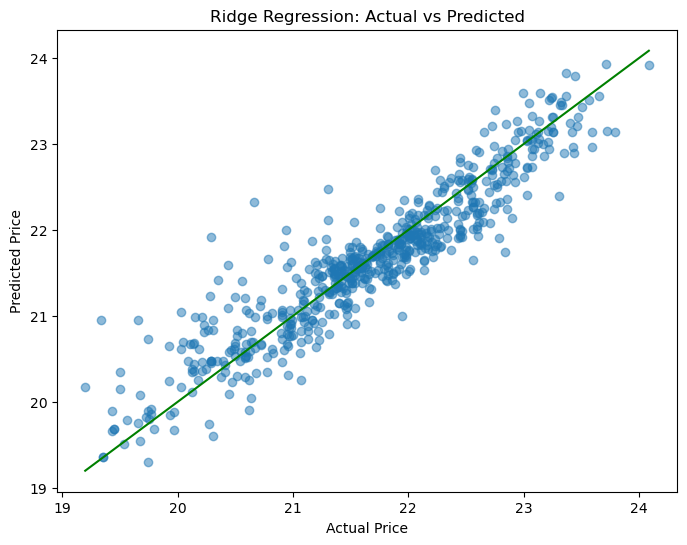

In [115]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_ridge, alpha=0.5)

 
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "g-"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Ridge Regression: Actual vs Predicted")

plt.show()

In [116]:
# این قسمت مدل رگرسیون خطی سادست
from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(X_train_poly, y_train)
y_pred = reg.predict(X_test_poly)

In [117]:
X_test_poly = poly.transform(X_test)
y_pred = reg.predict(X_test_poly)

In [118]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
print(f"R2 Score: {r2_score(y_test, y_pred)}")
print(f"MAE: {mean_absolute_error(y_test, y_pred)}")
print(f"MSE: {mean_squared_error(y_test, y_pred)}")

R2 Score: 0.8640799987724772
MAE: 0.2467033504470522
MSE: 0.12039745287401526


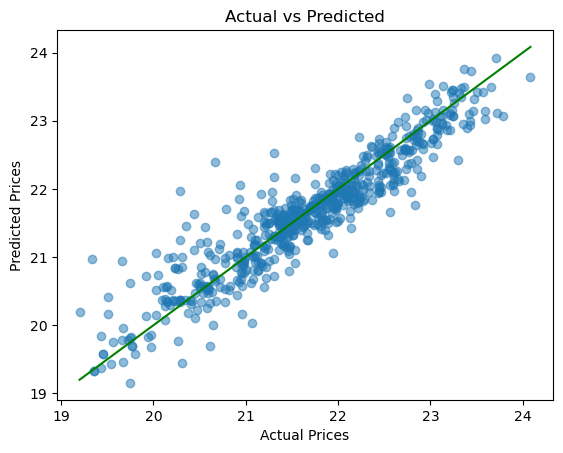

In [119]:
import matplotlib.pyplot as plt
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'g-') 
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted")
plt.show()

In [120]:
print("Linear Regression")
print("R2:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

print("\nRidge")
print("R2:", r2_score(y_test, y_pred_ridge))
print("MSE:", mean_squared_error(y_test, y_pred_ridge))

Linear Regression
R2: 0.8640799987724772
MSE: 0.12039745287401526

Ridge
R2: 0.8630356747915408
MSE: 0.12132251133593742


In [121]:
"""با وجود ضریب تعین یکسان در مدل ها تفاوت خیلی کمی میان 
تفاوت کوچکی توی MSE دو مدل مشاهده میشود 
و مدل poly عملکرد بهتری داشته 
هرچند این عملکرد آنچنان مشهود نیست
و البته بر MSE بدست آمده بر اساس
اعدای میباشد که با تابع لگاریتم فشرده شده اند و این مسئله مشخص نشده که تا چه مبلغی مدل امکان خطا دارد """

'با وجود ضریب تعین یکسان در مدل ها تفاوت خیلی کمی میان \nتفاوت کوچکی توی MSE دو مدل مشاهده میشود \nو مدل poly عملکرد بهتری داشته \nهرچند این عملکرد آنچنان مشهود نیست\nو البته بر MSE بدست آمده بر اساس\nاعدای میباشد که با تابع لگاریتم فشرده شده اند و این مسئله مشخص نشده که تا چه مبلغی مدل امکان خطا دارد '